In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
dataset_path = "/content/drive/MyDrive/KArSL-100"

import os

print(os.listdir(dataset_path))

['KARSL-100_Labels.xlsx', '01', '03', '02']


In [ ]:
print(os.listdir("/content/drive/MyDrive/KArSL-100/01"))

['train', 'test']


In [ ]:
print(os.listdir("/content/drive/MyDrive/KArSL-100/01/train"))

['0071-0170.7z']


In [ ]:
!apt-get install -y p7zip-full

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
p7zip-full is already the newest version (16.02+transitional.1).
0 upgraded, 0 newly installed, 0 to remove and 33 not upgraded.


In [ ]:
!7z x "/content/drive/MyDrive/KArSL-100/01/train/0071-0170.7z" -o"/content/train_data"


7-Zip 23.01 (x64) : Copyright (c) 1999-2023 Igor Pavlov : 2023-06-20
 64-bit locale=en_US.UTF-8 Threads:2 OPEN_MAX:1048576

Scanning the drive for archives:
  0M Scan /content/drive/MyDrive/KArSL-100/01/train/                                                    1 file, 1543997402 bytes (1473 MiB)

Extracting archive: /content/drive/MyDrive/KArSL-100/01/train/0071-0170.7z
--
Path = /content/drive/MyDrive/KArSL-100/01/train/0071-0170.7z
Type = 7z
Physical Size = 1543997402
Headers Size = 1862381
Method = LZMA2:25
Solid = +
Blocks = 1

  0%      0% 4306           1% 4306           2% 4306           3% 4306           4% 4306           5% 4306           6% 4306           7% 4306           8% 4306           9% 4306

In [ ]:
import os

print(os.listdir("/content/train_data")[:10])

['0148', '0168', '0074', '0087', '0127', '0129', '0075', '0102', '0166', '0097']


In [ ]:
import os
import pandas as pd

selected_classes = [
    "0092",  # hospital
    "0100",  # pharmacy
    "0134",  # sick
    "0132",  # medicine
    "0101",  # blood analysis
    "0102",  # physical examination
    "0103",  # sight examination
    "0105",  # stethoscope
    "0115",  # headache
    "0116",  # pain
    "0117",  # fever
    "0141",  # inoculation
    "0097",  # surgery
    "0155",  # hearing hindrance
    "0114",  # infection
    "0110"   # xray
]

data = []

for cls in selected_classes:
    class_path = os.path.join("/content/train_data", cls)

    if os.path.exists(class_path):
        samples = len([
            f for f in os.listdir(class_path)
            if os.path.isdir(os.path.join(class_path, f))
        ])

        data.append([cls, samples])

df = pd.DataFrame(data, columns=["Class", "Samples"])

display(df)

print("\nTotal Samples:", df["Samples"].sum())

,Class,Samples
0,0092,42
1,0100,42
2,0134,42
3,0132,42
4,0101,42
5,0102,42
6,0103,42
7,0105,42
8,0115,42
9,0116,42



Total Samples: 672


In [ ]:
import os
import pandas as pd

class_names = {
    "0092": "مستشفى",
    "0100": "صيدلية",
    "0134": "مريض",
    "0132": "دواء",
    "0101": "تحليل دم",
    "0102": "فحص سريري",
    "0103": "فحص النظر",
    "0105": "سماعة أذن",
    "0115": "صداع",
    "0116": "ألم",
    "0117": "حمى",
    "0141": "تطعيم",
    "0097": "عملية جراحية",
    "0155": "إعاقة سمعية",
    "0114": "عدوى",
    "0110": "صورة أشعة"
}

results = []

for cls, arabic_name in class_names.items():

    class_path = f"/content/train_data/{cls}"

    total_images = 0

    for sample in os.listdir(class_path):

        sample_path = os.path.join(class_path, sample)

        if os.path.isdir(sample_path):

            total_images += len([
                f for f in os.listdir(sample_path)
                if f.lower().endswith(".jpg")
            ])

    results.append([arabic_name, total_images])

df = pd.DataFrame(results, columns=["الكلمة", "عدد الصور"])

display(df)

print("إجمالي الصور:", df["عدد الصور"].sum())

,الكلمة,عدد الصور
0,مستشفى,1847
1,صيدلية,1454
2,مريض,1651
3,دواء,1354
4,تحليل دم,2362
5,فحص سريري,2967
6,فحص النظر,2463
7,سماعة أذن,1690
8,صداع,2502
9,ألم,1630


إجمالي الصور: 33701


In [ ]:
import os
import shutil

selected_classes = [
    "0092", "0100", "0134", "0132",
    "0101", "0102", "0103", "0105",
    "0115", "0116", "0117", "0141",
    "0097", "0155", "0114", "0110"
]

source_path = "/content/train_data"
target_path = "/content/medical_sign_dataset"

os.makedirs(target_path, exist_ok=True)

for cls in selected_classes:
    src = os.path.join(source_path, cls)
    dst = os.path.join(target_path, cls)

    if os.path.exists(src):
        shutil.copytree(src, dst, dirs_exist_ok=True)

print("Dataset created successfully!")

Dataset created successfully!


In [ ]:
print(len(os.listdir("/content/medical_sign_dataset")))

16


In [ ]:
import os
import pandas as pd

dataset_path = "/content/medical_sign_dataset"

class_counts = {}

for cls in sorted(os.listdir(dataset_path)):
    num_images = len(os.listdir(os.path.join(dataset_path, cls)))
    class_counts[cls] = num_images

df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

print(df)
print("\nTotal Images:", df["Images"].sum())

   Class  Images
0   0092      42
1   0097      42
2   0100      42
3   0101      42
4   0102      42
5   0103      42
6   0105      42
7   0110      43
8   0114      42
9   0115      42
10  0116      42
11  0117      42
12  0132      42
13  0134      42
14  0141      41
15  0155      42

Total Images: 672


In [ ]:
import os
import shutil
import random
from sklearn.model_selection import train_test_split

source_dir = "/content/medical_sign_dataset"

output_dir = "/content/split_dataset"

train_dir = os.path.join(output_dir, "train")
val_dir = os.path.join(output_dir, "val")
test_dir = os.path.join(output_dir, "test")

for d in [train_dir, val_dir, test_dir]:
    os.makedirs(d, exist_ok=True)

for class_name in os.listdir(source_dir):

    class_path = os.path.join(source_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    samples = os.listdir(class_path)

    train_samples, temp_samples = train_test_split(
        samples,
        test_size=0.30,
        random_state=42
    )

    val_samples, test_samples = train_test_split(
        temp_samples,
        test_size=0.50,
        random_state=42
    )

    for split_name, split_samples in [
        ("train", train_samples),
        ("val", val_samples),
        ("test", test_samples)
    ]:

        split_class_dir = os.path.join(output_dir, split_name, class_name)
        os.makedirs(split_class_dir, exist_ok=True)

        for sample in split_samples:
            shutil.copytree(
                os.path.join(class_path, sample),
                os.path.join(split_class_dir, sample),
                dirs_exist_ok=True
            )

print("Dataset split completed!")

Dataset split completed!


In [ ]:
for split in ["train", "val", "test"]:

    total = 0

    split_path = f"/content/split_dataset/{split}"

    for cls in os.listdir(split_path):
        total += len(os.listdir(os.path.join(split_path, cls)))

    print(split, total)

train 464
val 96
test 112


In [ ]:
!pip install albumentations

In [ ]:
import albumentations as A

train_transform = A.Compose([

    A.HorizontalFlip(p=0.5),  # 1

    A.Rotate(limit=15, p=0.5),  # 2

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),  # 3 + 4

    A.RandomScale(
        scale_limit=0.15,
        p=0.5
    ),  # 5

    A.ShiftScaleRotate(
        shift_limit=0.1,
        scale_limit=0.1,
        rotate_limit=10,
        p=0.5
    )  # 6

])

print("Train Augmentation Ready ✅")

Train Augmentation Ready ✅


/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


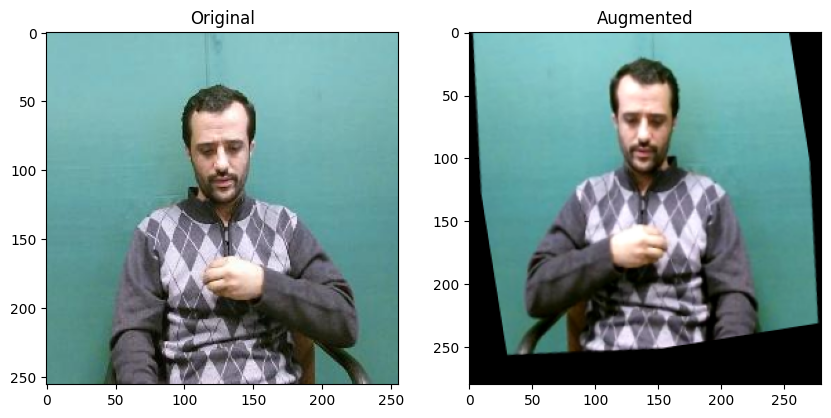

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os
import random

# اختيار كلاس عشوائي
class_folder = random.choice(os.listdir("/content/split_dataset/train"))

sample_folder = random.choice(
    os.listdir(f"/content/split_dataset/train/{class_folder}")
)

sample_path = f"/content/split_dataset/train/{class_folder}/{sample_folder}"

image_file = random.choice([
    f for f in os.listdir(sample_path)
    if f.endswith(".jpg")
])

image_path = os.path.join(sample_path, image_file)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

augmented = train_transform(image=image)["image"]

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(augmented)
plt.title("Augmented")

plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2

In [ ]:
print("GPU:", tf.config.list_physical_devices('GPU'))

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
train_path = "/content/medical_sign_dataset"

In [ ]:
selected_classes = [
    "0092","0100","0134","0132",
    "0101","0102","0103","0105",
    "0115","0116","0117","0141",
    "0097","0155","0114","0110"
]

for cls in selected_classes:
    cls_path = os.path.join(train_path, cls)

    if os.path.exists(cls_path):
        print(cls, len(os.listdir(cls_path)))

0092 42
0100 42
0134 42
0132 42
0101 42
0102 42
0103 42
0105 42
0115 42
0116 42
0117 42
0141 41
0097 42
0155 42
0114 42
0110 43


In [ ]:
import os
import pandas as pd

dataset_path = "/content/medical_sign_dataset"

class_counts = {}

for cls in sorted(os.listdir(dataset_path)):
    cls_path = os.path.join(dataset_path, cls)

    if os.path.isdir(cls_path):
        class_counts[cls] = len(os.listdir(cls_path))

df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

display(df)

print("Total Images:", df["Images"].sum())

,Class,Images
0,0092,42
1,0097,42
2,0100,42
3,0101,42
4,0102,42
5,0103,42
6,0105,42
7,0110,43
8,0114,42
9,0115,42


Total Images: 672


In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split

source_dir = "/content/medical_sign_dataset"
output_dir = "/content/final_dataset"

# حذف النتائج القديمة إذا موجودة
shutil.rmtree(output_dir, ignore_errors=True)

# إنشاء مجلدات train / val / test
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(output_dir, split), exist_ok=True)

# المرور على كل Class
for cls in os.listdir(source_dir):

    cls_path = os.path.join(source_dir, cls)

    if not os.path.isdir(cls_path):
        continue

    # المجلدات الفرعية (العينات)
    samples = os.listdir(cls_path)

    train_samples, temp_samples = train_test_split(
        samples,
        test_size=0.30,
        random_state=42
    )

    val_samples, test_samples = train_test_split(
        temp_samples,
        test_size=0.50,
        random_state=42
    )

    for split_name, split_samples in [
        ("train", train_samples),
        ("val", val_samples),
        ("test", test_samples)
    ]:

        dst_class = os.path.join(output_dir, split_name, cls)
        os.makedirs(dst_class, exist_ok=True)

        for sample in split_samples:

            src_folder = os.path.join(cls_path, sample)
            dst_folder = os.path.join(dst_class, sample)

            shutil.copytree(
                src_folder,
                dst_folder,
                dirs_exist_ok=True
            )

print("✅ Dataset split completed!")

✅ Dataset split completed!


In [ ]:
!pip install albumentations opencv-python -q

In [ ]:
import albumentations as A
from albumentations.pytorch import ToTensorV2

In [ ]:
train_transform = A.Compose([

    A.HorizontalFlip(p=0.5),

    A.RandomBrightnessContrast(
        brightness_limit=0.2,
        contrast_limit=0.2,
        p=0.5
    ),

    A.Rotate(
        limit=15,
        p=0.5
    ),

    A.ShiftScaleRotate(
        shift_limit=0.1,
        scale_limit=0.1,
        rotate_limit=10,
        p=0.5
    ),

    A.GaussNoise(
        p=0.3
    ),

    A.RandomResizedCrop(
        size=(224,224),
        scale=(0.8,1.0),
        p=0.5
    )

])

/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


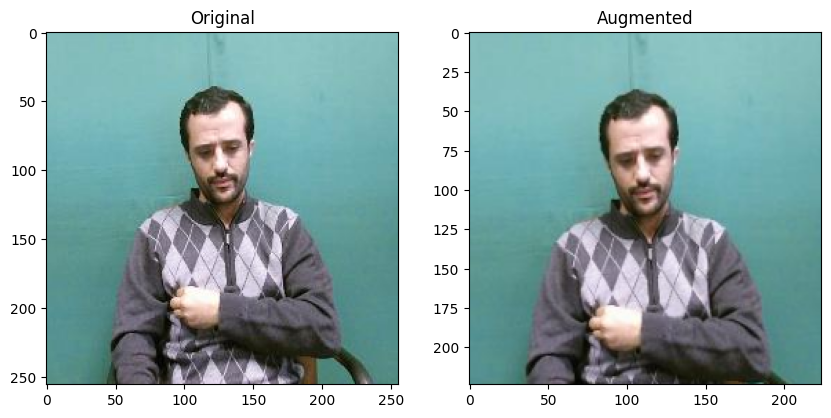

In [ ]:
import cv2
import matplotlib.pyplot as plt
import os

sample_class = os.listdir("/content/final_dataset/train")[0]

sample_folder = os.listdir(
    f"/content/final_dataset/train/{sample_class}"
)[0]

sample_image = os.listdir(
    f"/content/final_dataset/train/{sample_class}/{sample_folder}"
)[0]

img_path = f"/content/final_dataset/train/{sample_class}/{sample_folder}/{sample_image}"

image = cv2.imread(img_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

augmented = train_transform(image=image)["image"]

plt.figure(figsize=(10,5))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Original")

plt.subplot(1,2,2)
plt.imshow(augmented)
plt.title("Augmented")

plt.show()

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

In [ ]:
train_dir = "/content/final_dataset/train"
val_dir = "/content/final_dataset/val"
test_dir = "/content/final_dataset/test"

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1./255
)

val_test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical"
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

Found 23346 images belonging to 16 classes.
Found 4682 images belonging to 16 classes.
Found 5673 images belonging to 16 classes.


In [ ]:
print(train_generator.class_indices)
print("Number of Classes =", len(train_generator.class_indices))

{'0092': 0, '0097': 1, '0100': 2, '0101': 3, '0102': 4, '0103': 5, '0105': 6, '0110': 7, '0114': 8, '0115': 9, '0116': 10, '0117': 11, '0132': 12, '0134': 13, '0141': 14, '0155': 15}
Number of Classes = 16


In [ ]:
print(train_dir)
print(val_dir)
print(test_dir)

/content/final_dataset/train
/content/final_dataset/val
/content/final_dataset/test


In [ ]:
import os

print(os.path.exists(train_dir))
print(os.path.exists(val_dir))
print(os.path.exists(test_dir))

True
True
True


In [ ]:
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical"
)

val_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical"
)

test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=(224, 224),
    batch_size=16,
    class_mode="categorical",
    shuffle=False
)

Found 23346 images belonging to 16 classes.
Found 4682 images belonging to 16 classes.
Found 5673 images belonging to 16 classes.


In [ ]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

In [ ]:
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
x = base_model.output
x = GlobalAveragePooling2D()(x)

x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)

predictions = Dense(
    train_generator.num_classes,
    activation="softmax"
)(x)

model = Model(
    inputs=base_model.input,
    outputs=predictions
)

In [ ]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,424,016 (9.25 MB)

 Trainable params: 166,032 (648.56 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint

checkpoint = ModelCheckpoint(
    "best_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[checkpoint]
)

Epoch 1/10
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.8713 - loss: 0.4555
Epoch 1: val_accuracy improved from None to 1.00000, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 103s 61ms/step - accuracy: 0.9616 - loss: 0.1460 - val_accuracy: 1.0000 - val_loss: 0.0022
Epoch 2/10
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9968 - loss: 0.0156
Epoch 2: val_accuracy did not improve from 1.00000
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 75s 51ms/step - accuracy: 0.9945 - loss: 0.0229 - val_accuracy: 0.9930 - val_loss: 0.0211
Epoch 3/10
1459/1460 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9942 - loss: 0.0171
Epoch 3: val_accuracy did not improve from 1.00000
1460/1460 ━━━━━━━━━━━━━━━━━━━━ 73s 50ms/step - accuracy: 0.9958 - loss: 0.0137 - val_accuracy: 0.9972 - val_loss: 0.0091
Epoch 4/10
1459/1460 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.9939 - loss: 0.0162
Epoch 4: val_accuracy did not improve fr

In [ ]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


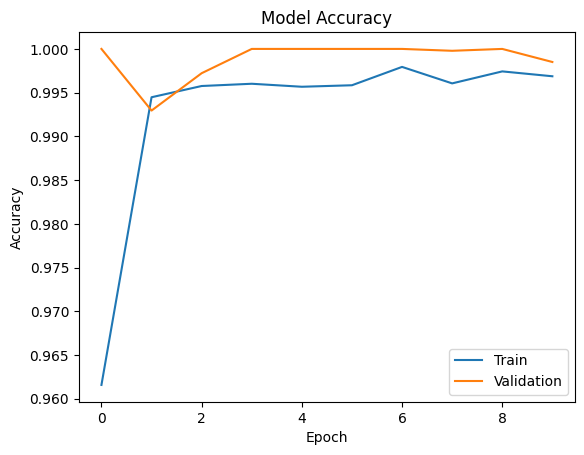

In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])

plt.show()

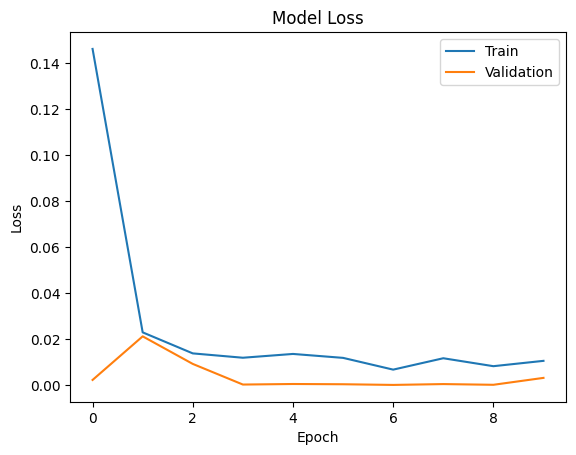

In [ ]:
# Loss

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'])

plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)

print("Test Accuracy:", test_acc)
print("Test Loss:", test_loss)

355/355 ━━━━━━━━━━━━━━━━━━━━ 19s 54ms/step - accuracy: 0.9995 - loss: 0.0013
Test Accuracy: 0.9994711875915527
Test Loss: 0.0013317354023456573


In [ ]:
import numpy as np

predictions = model.predict(test_generator)

y_pred = np.argmax(predictions, axis=1)

y_true = test_generator.classes

355/355 ━━━━━━━━━━━━━━━━━━━━ 21s 50ms/step


In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=list(test_generator.class_indices.keys())
    )
)

              precision    recall  f1-score   support

        0092       0.99      1.00      1.00       299
        0097       1.00      1.00      1.00       443
        0100       1.00      1.00      1.00       236
        0101       1.00      1.00      1.00       426
        0102       1.00      1.00      1.00       493
        0103       1.00      1.00      1.00       405
        0105       1.00      1.00      1.00       288
        0110       1.00      1.00      1.00       660
        0114       1.00      1.00      1.00       326
        0115       1.00      1.00      1.00       425
        0116       1.00      1.00      1.00       302
        0117       1.00      1.00      1.00       336
        0132       1.00      1.00      1.00       224
        0134       1.00      1.00      1.00       278
        0141       1.00      1.00      1.00       236
        0155       1.00      1.00      1.00       296

    accuracy                           1.00      5673
   macro avg       1.00   

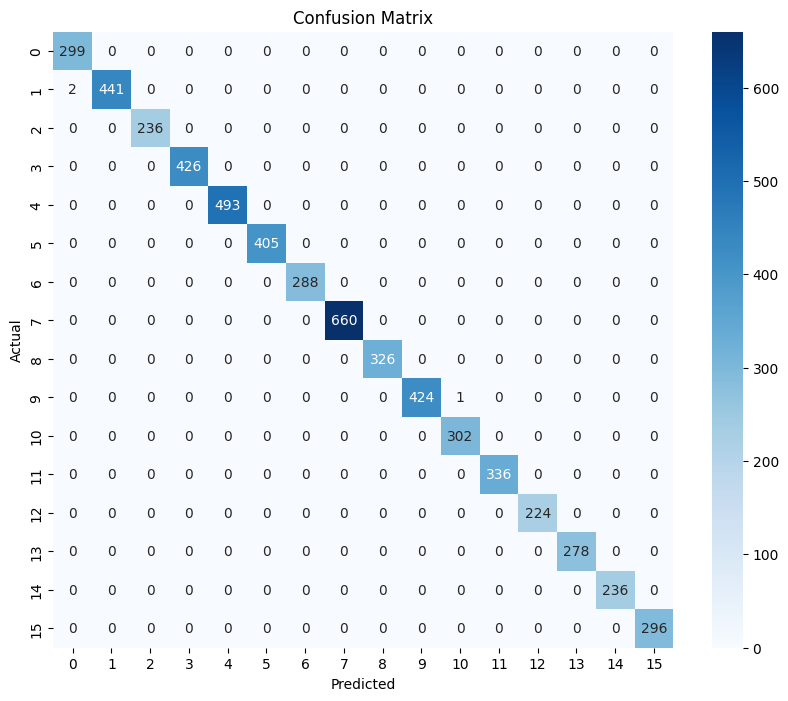

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [ ]:
model.save(
"/content/drive/MyDrive/medical_sign_model.keras"
)

In [ ]:
from tensorflow.keras.models import load_model

model = load_model('/content/drive/MyDrive/medical_sign_model.keras')

In [ ]:
class_names = [
    "مستشفى",
    "عملية جراحية",
    "صيدلية",
    "تحليل دم",
    "فحص سريري",
    "فحص نظر",
    "سماعة أذن",
    "أشعة",
    "عدوى",
    "صداع",
    "ألم",
    "حمى",
    "دواء",
    "مريض",
    "تطعيم",
    "إعاقة سمعية"
]

In [ ]:
import numpy as np

def predict_sign(img):

    img = img.resize((224,224))

    img = np.array(img)

    img = img / 255.0

    img = np.expand_dims(img, axis=0)

    prediction = model.predict(img, verbose=0)

    predicted_class = np.argmax(prediction)

    confidence = np.max(prediction)

    return f"{class_names[predicted_class]} | نسبة الثقة: {confidence*100:.2f}%"

In [ ]:
!pip install gradio -q

In [ ]:
import gradio as gr

In [ ]:
app = gr.Interface(
    fn=predict_sign,
    inputs=gr.Image(type="pil"),
    outputs=gr.Textbox(),
    title="وصـل | مساعد الاستقبال للصم",
    description="ارفع صورة لإشارة طبية وسيقوم النظام بالتعرف عليها"
)

In [ ]:
app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://45660c591f7bed1e37.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
from IPython.display import Javascript, display
from google.colab.output import eval_js
from base64 import b64decode
import cv2
import numpy as np
from PIL import Image

In [ ]:
def take_photo(filename='photo.jpg', quality=0.8):

    js = Javascript('''
    async function takePhoto(quality) {

      const div = document.createElement('div');
      const capture = document.createElement('button');
      capture.textContent = 'Capture';
      div.appendChild(capture);

      const video = document.createElement('video');
      video.style.display = 'block';

      const stream =
          await navigator.mediaDevices.getUserMedia({video: true});

      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();

      google.colab.output.setIframeHeight(document.body.scrollHeight, true);

      await new Promise((resolve) => capture.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;

      canvas.getContext('2d').drawImage(video, 0, 0);

      stream.getVideoTracks()[0].stop();
      div.remove();

      return canvas.toDataURL('image/jpeg', quality);
    }
    ''')

    display(js)

    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])

    with open(filename, 'wb') as f:
        f.write(binary)

    return filename

In [ ]:
from tensorflow.keras.preprocessing import image

photo_path = take_photo()

img = image.load_img(
    photo_path,
    target_size=(224,224)
)

img_array = image.img_to_array(img)
img_array = img_array / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

predicted_class = np.argmax(prediction)

confidence = np.max(prediction)

print("الكلمة المتوقعة:")
print(class_names[predicted_class])

print("نسبة الثقة:")
print(round(confidence * 100, 2), "%")

<IPython.core.display.Javascript object>

MessageError: NotAllowedError: The request is not allowed by the user agent or the platform in the current context, possibly because the user denied permission.